In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from collections import defaultdict, Counter
import math

In [5]:
path = r'.\out_test\results_paper.json'

In [6]:
with open(path, 'r') as f:
    data = f.read()
    data = eval(data)

In [7]:
print(len(data)/10000*100,'% Agreement Rate')

99.02 % Agreement Rate


In [8]:
import numpy as np
import matplotlib.pyplot as plt

def plot_convergence_cycles(runs, bins=None):
    final_rounds = np.array([run["rounds"][-1] for run in runs], dtype=int)
    final_cycles = final_rounds // 2  # 0,1,2,... cycles

    unique_sorted = np.sort(np.unique(final_cycles))
    cum = [(final_cycles <= c).mean() for c in unique_sorted]

    plt.figure(figsize=(6,4))
    plt.step(unique_sorted, cum, where="post")
    plt.xlabel("final negotiation cycle (Provider+Consumer)")
    plt.ylabel("fraction of runs completed")
    plt.title("Convergence (CDF of final cycle)")
    plt.ylim(0, 1.01)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6,4))
    plt.hist(final_cycles, bins=bins if bins else len(unique_sorted))
    plt.xlabel("final negotiation cycle (Provider+Consumer)")
    plt.ylabel("number of runs")
    plt.title("Distribution of final cycles")
    plt.tight_layout()
    plt.show()

    idx95 = np.where(np.array(cum) >= 0.95)[0][0]
    return int(unique_sorted[idx95])


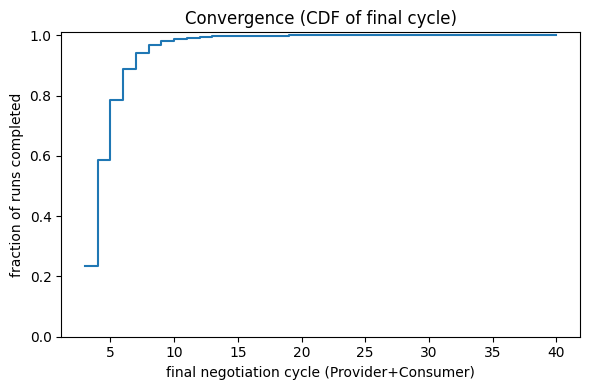

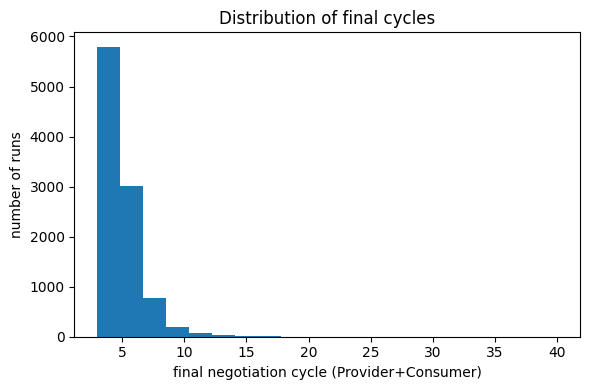

8

In [112]:
plot_convergence_cycles(data)

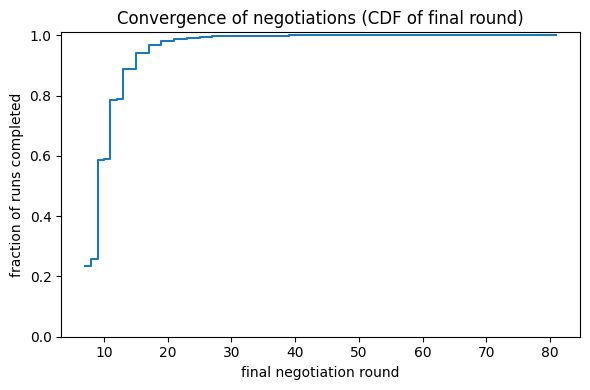

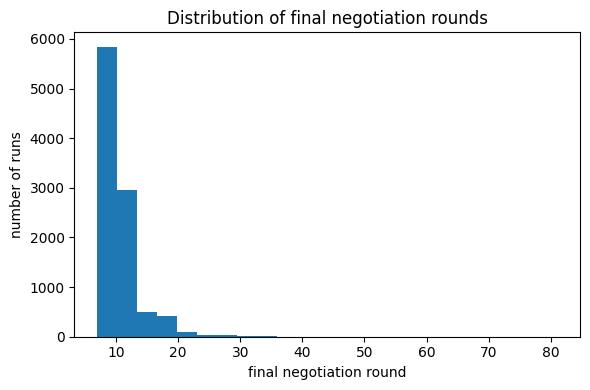

In [129]:
def plot_convergence_rounds(runs, bins=None):
    final_rounds = [run["rounds"][-1] for run in runs]

    # CDF: ποσοστό runs που έχουν τελειώσει μέχρι κάθε γύρο
    unique_sorted = sorted(set(final_rounds))
    cum = []
    for r in unique_sorted:
        frac = sum(fr <= r for fr in final_rounds) / len(final_rounds)
        cum.append(frac)

    plt.figure(figsize=(6,4))
    plt.step(unique_sorted, cum, where="post")
    plt.xlabel("final negotiation round")
    plt.ylabel("fraction of runs completed")
    plt.title("Convergence of negotiations (CDF of final round)")
    plt.ylim(0, 1.01)
    plt.tight_layout()

    # Extra: histogram (προαιρετικά)
    plt.figure(figsize=(6,4))
    plt.hist(final_rounds, bins=bins if bins else len(unique_sorted))
    plt.xlabel("final negotiation round")
    plt.ylabel("number of runs")
    plt.title("Distribution of final negotiation rounds")
    plt.tight_layout()
    return unique_sorted[int(np.where(np.array(cum)>0.99)[0][0])]

round95 = plot_convergence_rounds(data) 

In [130]:
round95

23

In [131]:

def is_consumer_round(r: float) -> bool:
    """True αν ο γύρος είναι consumer, δηλαδή 1.5, 2.5 κτλ."""
    return r%2==0
    # return not math.isclose(r, round(r), rel_tol=0, abs_tol=1e-9)

# --- time / durations ---

def parse_pt_to_minutes(s: str) -> float:
    """
    ISO 8601 duration π.χ. "PT21M55.529S" -> λεπτά (float).
    """
    s = s.replace("PT", "")
    minutes, seconds = 0.0, 0.0
    if "M" in s:
        m_part, rest = s.split("M", 1)
        minutes = float(m_part)
        s = rest
    if "S" in s and s:
        s_part = s.replace("S", "")
        if s_part:
            seconds = float(s_part)
    return minutes + seconds / 60.0

def normalize_cat(v):
    """Κάνει string ή list σε σταθερό string (για categories)."""
    if isinstance(v, list):
        return "+".join(sorted(map(str, v)))
    return str(v)


In [132]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
import isodate
from collections import defaultdict

def mad(xs):
    xs = np.array(xs)
    med = np.median(xs)
    return np.median(np.abs(xs - med))


def minutes_to_iso8601(m):
    """Convert minutes (float) → ISO 8601 duration, e.g. PT20M33.4S"""
    return isodate.duration_isoformat(timedelta(minutes=m))


def plot_round_trend_numeric(
    runs,
    key,
    transform=None,
    ylabel=None,
    use_iso_yaxis=False,
    max_labels=6,
    *,
    outfile: str = "round_trend.png",
    dpi: int = 300,
):
    """
    key: 'absoluteSize', 'count', 'delayPeriod', ...
    transform: optional conversion BEFORE stats (e.g. parse_pt_to_minutes)
    use_iso_yaxis: if True → Y-axis shown in ISO 8601 format (for delayPeriod)
    outfile: path to save PNG
    """

    prov_vals_by_round = defaultdict(list)
    cons_vals_by_round = defaultdict(list)

    for run in runs:
        rounds = run["rounds"]
        values = run["data"][key]

        if rounds[-1] > round95:
            continue

        for r, v in zip(rounds, values):
            if transform:
                v = transform(v)
            try:
                val = float(v)
            except Exception:
                continue
            

            if is_consumer_round(r):
                cons_vals_by_round[r].append(val)
            else:
                prov_vals_by_round[r].append(val)

    prov_rounds = sorted(prov_vals_by_round)
    cons_rounds = sorted(cons_vals_by_round)

    prov_mean = [np.mean(prov_vals_by_round[r]) for r in prov_rounds]
    cons_mean = [np.mean(cons_vals_by_round[r]) for r in cons_rounds]

    Np = max((len(v) for v in prov_vals_by_round.values()), default=1)
    Nc = max((len(v) for v in cons_vals_by_round.values()), default=1)

    prov_std = [
        np.std(prov_vals_by_round[r], ddof=1) * np.sqrt(len(prov_vals_by_round[r]) / Np)
        if len(prov_vals_by_round[r]) >= 5 else 0.0
        for r in prov_rounds
    ]

    cons_std = [
        np.std(cons_vals_by_round[r], ddof=1) * np.sqrt(len(cons_vals_by_round[r]) / Nc)
        if len(cons_vals_by_round[r]) >= 5 else 0.0
        for r in cons_rounds
    ]

    plt.figure(figsize=(7, 4))

    if prov_rounds:
        plt.plot(prov_rounds, prov_mean, marker="o", linestyle="-", label="Provider")
        plt.fill_between(
            prov_rounds,
            np.array(prov_mean) - np.array(prov_std),
            np.array(prov_mean) + np.array(prov_std),
            alpha=0.15,
        )

    if cons_rounds:
        plt.plot(cons_rounds, cons_mean, marker="s", linestyle="--", label="Consumer")
        plt.fill_between(
            cons_rounds,
            np.array(cons_mean) - np.array(cons_std),
            np.array(cons_mean) + np.array(cons_std),
            alpha=0.15,
        )

    plt.xlabel("Round")
    plt.ylabel(ylabel if ylabel else key)
    plt.legend()

    if use_iso_yaxis:
        ax = plt.gca()
        yticks = ax.get_yticks()
        yticks = yticks[::max(1, len(yticks) // max_labels)]
        ax.set_yticks(yticks)
        ax.set_yticklabels([minutes_to_iso8601(v) for v in yticks])

    plt.tight_layout()
    plt.savefig(outfile, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()


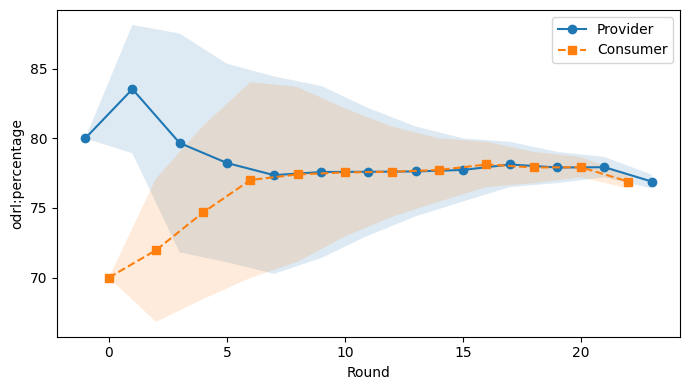

In [133]:
plot_round_trend_numeric(
    data,
    key="percentage",
    ylabel="odrl:percentage",
    outfile="percentage.png",
)

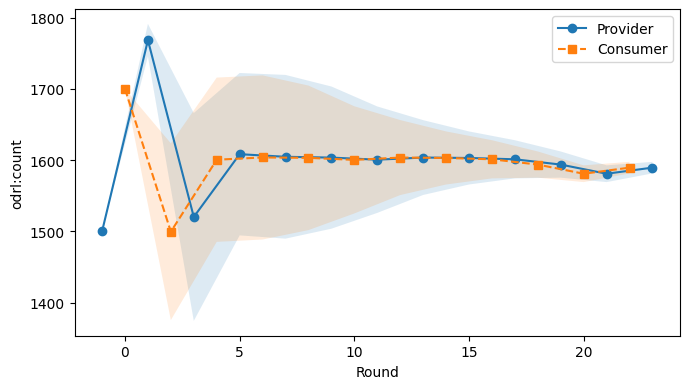

In [134]:
plot_round_trend_numeric(
    data,
    key="count",
    ylabel="odrl:count",    
    outfile="count.png",

)

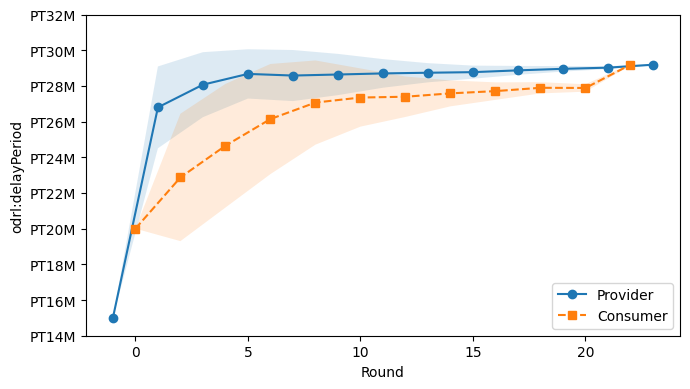

In [135]:
plot_round_trend_numeric(
    data,
    key="delayPeriod",
    transform=parse_pt_to_minutes,
    ylabel="odrl:delayPeriod",
    outfile="delay.png",
    use_iso_yaxis=True                       # ← 💣 show as ISO 8601 on Y-axis
)

In [136]:
def plot_round_trend_durations(runs):
    prov_vals_by_round = defaultdict(list)
    cons_vals_by_round = defaultdict(list)

    for run in runs:
        rounds = run["rounds"]
    
        prov_durs = run["durations"]["provider"]
        cons_durs = run["durations"]["consumer"]

        # Υποθέτω: provider durations αντιστοιχούν σε integer rounds
        # και consumer σε .5 rounds, με ίδια σειρά.
        # Αν όχι ακριβώς, προσαρμόζεις το mapping.

        prov_rounds = [r for r in rounds if not is_consumer_round(r)]
        cons_rounds = [r for r in rounds if is_consumer_round(r)]

        for r, d in zip(prov_rounds, prov_durs):
            prov_vals_by_round[r].append(float(d))

        for r, d in zip(cons_rounds, cons_durs):
            cons_vals_by_round[r].append(float(d))

    prov_rounds = sorted(prov_vals_by_round.keys())
    cons_rounds = sorted(cons_vals_by_round.keys())

    prov_mean = [np.median(prov_vals_by_round[r]) for r in prov_rounds]
    prov_std  = [np.std (prov_vals_by_round[r]) for r in prov_rounds]

    cons_mean = [np.median(cons_vals_by_round[r]) for r in cons_rounds]
    cons_std  = [np.std (cons_vals_by_round[r]) for r in cons_rounds]

    plt.figure(figsize=(7,4))
    if prov_rounds:
        plt.plot(prov_rounds, prov_mean, marker="o",
                 label="provider duration")
        plt.fill_between(prov_rounds,
                         np.array(prov_mean)-np.array(prov_std),
                         np.array(prov_mean)+np.array(prov_std),
                         alpha=0.15)
    if cons_rounds:
        plt.plot(cons_rounds, cons_mean, marker="s",
                 linestyle="--", label="consumer duration")
        plt.fill_between(cons_rounds,
                         np.array(cons_mean)-np.array(cons_std),
                         np.array(cons_mean)+np.array(cons_std),
                         alpha=0.15)
    plt.xlabel("round")
    plt.ylabel("duration (seconds)")
    plt.title("Duration to send counter offer (mean ± std)")
    plt.legend()
    plt.tight_layout()


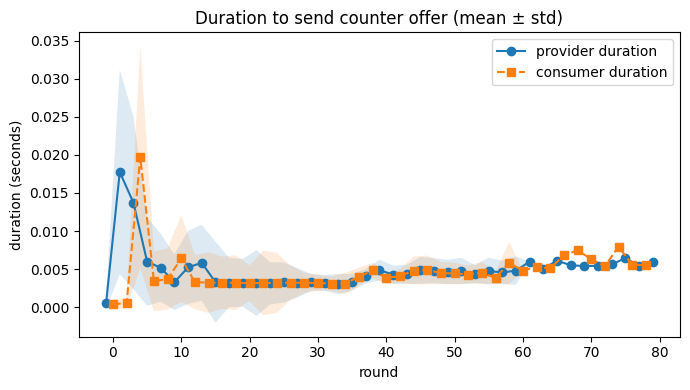

In [137]:
plot_round_trend_durations(data)

In [138]:
import matplotlib.dates as mdates
import numpy as np
from collections import defaultdict
from datetime import datetime
import matplotlib.pyplot as plt

def plot_round_trend_absoluteTemporalPosition(
    runs,
    *,
    outfile: str = "absoluteTemporalPosition_trend.png",
    dpi: int = 300,
):
    prov_vals_by_round = defaultdict(list)
    cons_vals_by_round = defaultdict(list)

    for run in runs:
        rounds = run["rounds"]
        if rounds[-1] > round95:
            continue

        dates = [datetime.fromisoformat(d)
                 for d in run["data"]["absoluteTemporalPosition"]]

        for r, dt in zip(rounds, dates):
            if is_consumer_round(r):
                cons_vals_by_round[r].append(dt)
            else:
                prov_vals_by_round[r].append(dt)

    def stats_for_dict_scaled(d):
        xs = sorted(d.keys())
        means = []
        stds_scaled = []

        if not d:
            return [], np.array([]), np.array([])

        N_max = max(len(v) for v in d.values())

        for r in xs:
            ts = np.array([dt.timestamp() for dt in d[r]])
            mean_ts = ts.mean()
            std_ts = ts.std(ddof=1) if len(ts) > 1 else 0.0

            std_scaled = std_ts * np.sqrt(len(ts) / max(1, N_max))

            means.append(mean_ts)
            stds_scaled.append(std_scaled)

        return xs, np.array(means), np.array(stds_scaled)

    prov_rounds, prov_mean_ts, prov_std_ts = stats_for_dict_scaled(prov_vals_by_round)
    cons_rounds, cons_mean_ts, cons_std_ts = stats_for_dict_scaled(cons_vals_by_round)

    plt.figure(figsize=(7, 4))
    ax = plt.gca()

    if prov_rounds:
        prov_mean_dt = [datetime.fromtimestamp(t) for t in prov_mean_ts]
        plt.plot(prov_rounds, prov_mean_dt, marker="o", label="Provider")
        plt.fill_between(
            prov_rounds,
            [datetime.fromtimestamp(t) for t in (prov_mean_ts - prov_std_ts)],
            [datetime.fromtimestamp(t) for t in (prov_mean_ts + prov_std_ts)],
            alpha=0.15
        )

    if cons_rounds:
        cons_mean_dt = [datetime.fromtimestamp(t) for t in cons_mean_ts]
        plt.plot(cons_rounds, cons_mean_dt, marker="s", linestyle="--", label="Consumer")
        plt.fill_between(
            cons_rounds,
            [datetime.fromtimestamp(t) for t in (cons_mean_ts - cons_std_ts)],
            [datetime.fromtimestamp(t) for t in (cons_mean_ts + cons_std_ts)],
            alpha=0.15
        )

    ax.yaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    plt.xlabel("Round")
    plt.ylabel("odrl:absoluteTemporalPosition")
    plt.legend()
    plt.tight_layout()

    # ✅ save AND show
    plt.savefig(outfile, dpi=dpi, bbox_inches="tight")
    plt.show()


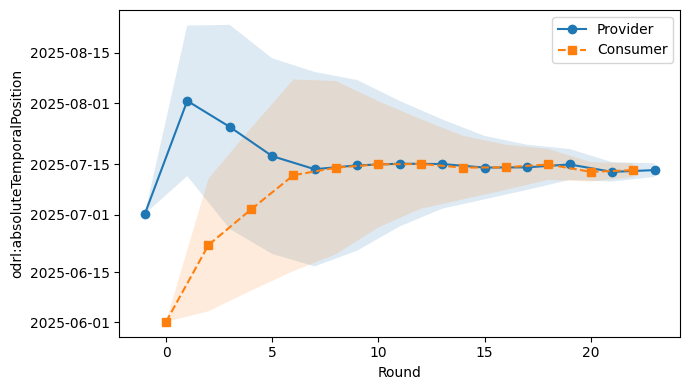

In [139]:
plot_round_trend_absoluteTemporalPosition(data)

In [140]:
round95

23

In [141]:
import numpy as np

def smooth_series(xs, window=3):
    """
    Simple centered moving average smoothing.
    Preserves length and avoids edge shrinkage.
    """
    xs = np.asarray(xs, dtype=float)
    if window <= 1 or len(xs) < window:
        return xs.tolist()

    pad = window // 2
    xs_pad = np.pad(xs, (pad, pad), mode="edge")
    kernel = np.ones(window) / window
    smoothed = np.convolve(xs_pad, kernel, mode="valid")
    return smoothed.tolist()

def plot_category_lines_per_round(
    runs,
    key,
    title=None,          # kept for compatibility but ignored
    smooth=True,
    min_share=0.0,
    *,
    outfile: str = None,
    dpi: int = 300,
):
    # 1) collect all rounds
    # 1) collect all rounds
    all_rounds = sorted({r for run in runs for r in run["rounds"] if r < round95})
    all_rounds_idx = list(np.where(np.array(all_rounds) < round95)[0])
    
    # 2) collect all categories for this key
    categories = sorted({
        normalize_cat(v)
        for run in runs
        for v in run["data"][key]
    })

    # 3) compute fraction per category per round
    frac_per_cat = {cat: [] for cat in categories}
    
    for r in all_rounds:
        vals = []
        for run in runs:
            if run["rounds"][-1] > round95:
                continue
            if r in run["rounds"]:
                idx = run["rounds"].index(r)

                vals.append(normalize_cat(run["data"][key][idx]))

        if vals:
            counts = Counter(vals)
            total = len(vals)
            for cat in categories:
                frac_per_cat[cat].append(counts.get(cat, 0) / total)
        else:
            for cat in categories:
                frac_per_cat[cat].append(0.0)

    # 4) optional smoothing
    if smooth:
        for cat in categories:
            frac_per_cat[cat] = smooth_series(frac_per_cat[cat], window=3)

    # 5) drop categories that almost never appear
    categories = [cat for cat in categories if max(frac_per_cat[cat]) >= min_share]

    # 6) plot
    plt.figure(figsize=(10, 5))
    for cat in categories:
        plt.plot(all_rounds, frac_per_cat[cat], marker="o", linewidth=1.5, label=cat)

    plt.xlabel("Round")
    plt.ylabel(f"odrl:{key} percentage of occurence per round")
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.2)
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()

    # ✅ save AND show (no title)
    if outfile is None:
        outfile = f"{cat}_distribution_per_round.png"
    plt.savefig(outfile, dpi=dpi, bbox_inches="tight")
    plt.show()


In [142]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def smooth_series(xs, window=3):
    """Centered moving average smoothing, length-preserving."""
    xs = np.asarray(xs, dtype=float)
    if window <= 1 or len(xs) < window:
        return xs.tolist()
    pad = window // 2
    xs_pad = np.pad(xs, (pad, pad), mode="edge")
    kernel = np.ones(window) / window
    return np.convolve(xs_pad, kernel, mode="valid").tolist()

def plot_category_area_per_round(
    runs,
    key,
    *,
    round95=None,
    smooth=True,
    smooth_window=3,
    min_share=0.0,
    include_rounds=None,   # e.g., lambda r: r >= 1 to exclude init rounds
    normalize_to_one=True, # renormalize visible categories to stack to 1
    order="final",         # "final" | "max" | "alpha"
    alpha=0.85,
    outfile=None,
    dpi=300,
):
    """
    Stacked area plot: fraction of each category per round across runs.

    Requires:
      - runs: list of dicts with run["rounds"] and run["data"][key]
      - normalize_cat(v): your canonicalizer for enum/set values
      - (optional) global round95 cutoff (or pass round95=...)

    Notes:
      - If some categories are filtered out via min_share, setting normalize_to_one=True
        will renormalize the remaining fractions per round so the stack sums to 1.0.
      - include_rounds lets you explicitly control which rounds are plotted.
    """

    if round95 is None:
        # fallback: infer max observed round + 1 (safe default if you forgot to pass)
        round95 = max(max(run["rounds"]) for run in runs) + 1

    # 1) collect all rounds (KEEP round numbers; no np.where indexing bug)
    all_rounds = sorted({r for run in runs for r in run["rounds"] if r < round95})
    if include_rounds is not None:
        all_rounds = [r for r in all_rounds if include_rounds(r)]

    # 2) collect categories from observed values
    categories = sorted({
        normalize_cat(v)
        for run in runs
        for v in run["data"][key]
    })

    # 3) compute fraction per category per round
    frac_per_cat = {cat: [] for cat in categories}

    for r in all_rounds:
        vals = []
        for run in runs:
            # keep your existing "truncate long negotiations" logic if needed
            if run["rounds"][-1] > round95:
                continue
            if r in run["rounds"]:
                idx = run["rounds"].index(r)
                vals.append(normalize_cat(run["data"][key][idx]))

        if vals:
            counts = Counter(vals)
            total = len(vals)
            for cat in categories:
                frac_per_cat[cat].append(counts.get(cat, 0) / total)
        else:
            for cat in categories:
                frac_per_cat[cat].append(0.0)

    # 4) optional smoothing
    if smooth:
        for cat in categories:
            frac_per_cat[cat] = smooth_series(frac_per_cat[cat], window=smooth_window)

    # 5) drop categories that almost never appear
    categories = [cat for cat in categories if max(frac_per_cat[cat]) >= float(min_share)]

    # optional ordering for nicer stacked look
    if order == "final":
        categories = sorted(categories, key=lambda c: frac_per_cat[c][-1])
    elif order == "max":
        categories = sorted(categories, key=lambda c: max(frac_per_cat[c]))
    else:  # "alpha"
        categories = sorted(categories)

    # 6) build stack matrix
    Y = np.array([frac_per_cat[cat] for cat in categories], dtype=float)  # (K, T)

    # if we filtered categories, stack may not sum to 1 -> optionally renormalize
    if normalize_to_one and Y.size > 0:
        colsum = Y.sum(axis=0, keepdims=True)
        colsum[colsum == 0.0] = 1.0
        Y = Y / colsum

    
    # 7) plot: stacked area
    fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)

    # --- soft color palette ---
    cmap = plt.get_cmap("Set3")  # or "Set3"
    colors = [cmap(i) for i in np.linspace(0, 1, len(categories))]

    ax.stackplot(
        all_rounds,
        Y,
        labels=[str(c) for c in categories],
        colors=colors,
        alpha=0.75,
        linewidth=0.0,
    )

    ax.set_xlabel("Round")
    ax.set_ylabel(f"odrl:{key} fraction per round")

    ax.set_ylim(
        0.0,
        1.0 if normalize_to_one else min(
            1.02,
            max(1.0, float(Y.sum(axis=0).max() if Y.size else 1.0))
        ),
    )

    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
    )

    fig.tight_layout()
    if outfile is None:
        outfile = f"{key}_area_distribution_per_round.png"

    fig.savefig(outfile, dpi=dpi, bbox_inches="tight")
    plt.show()



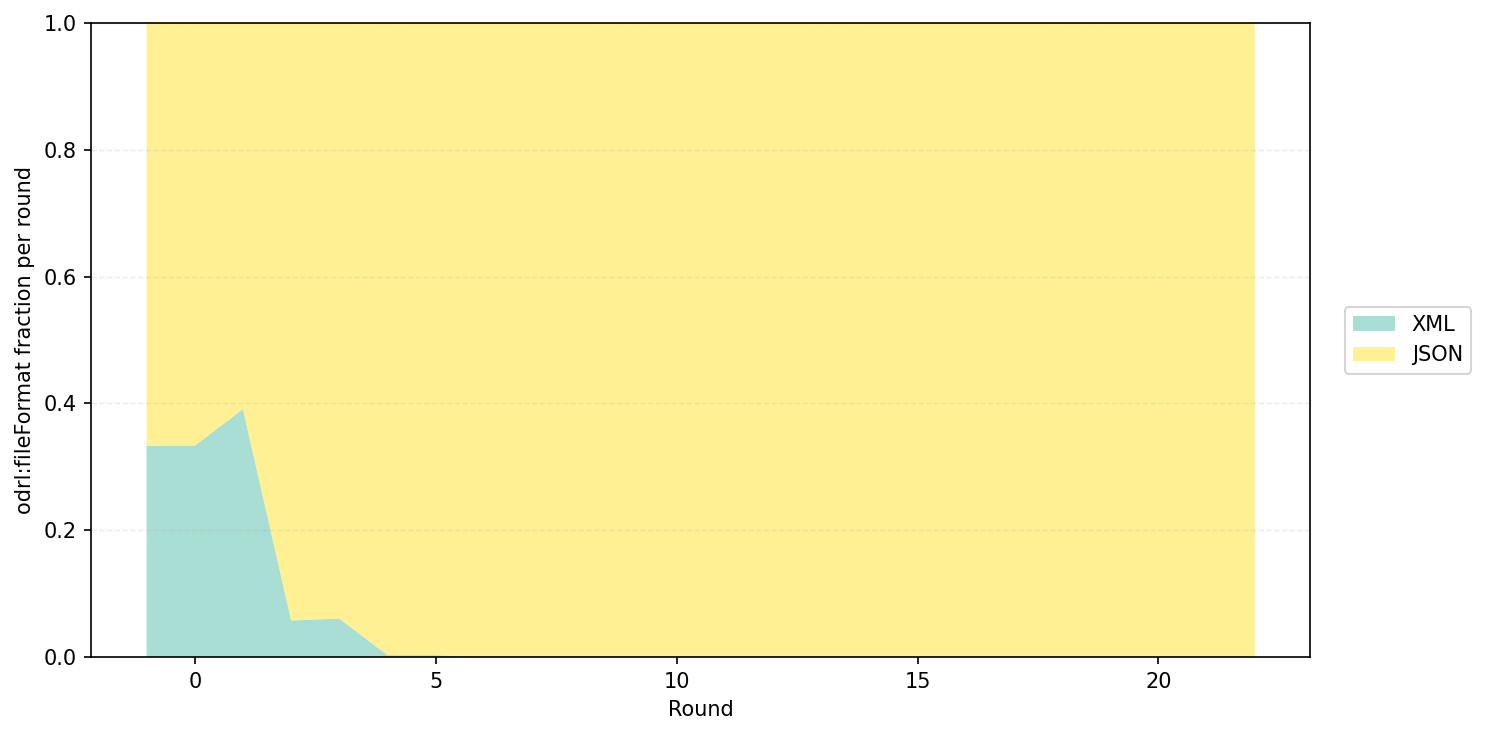

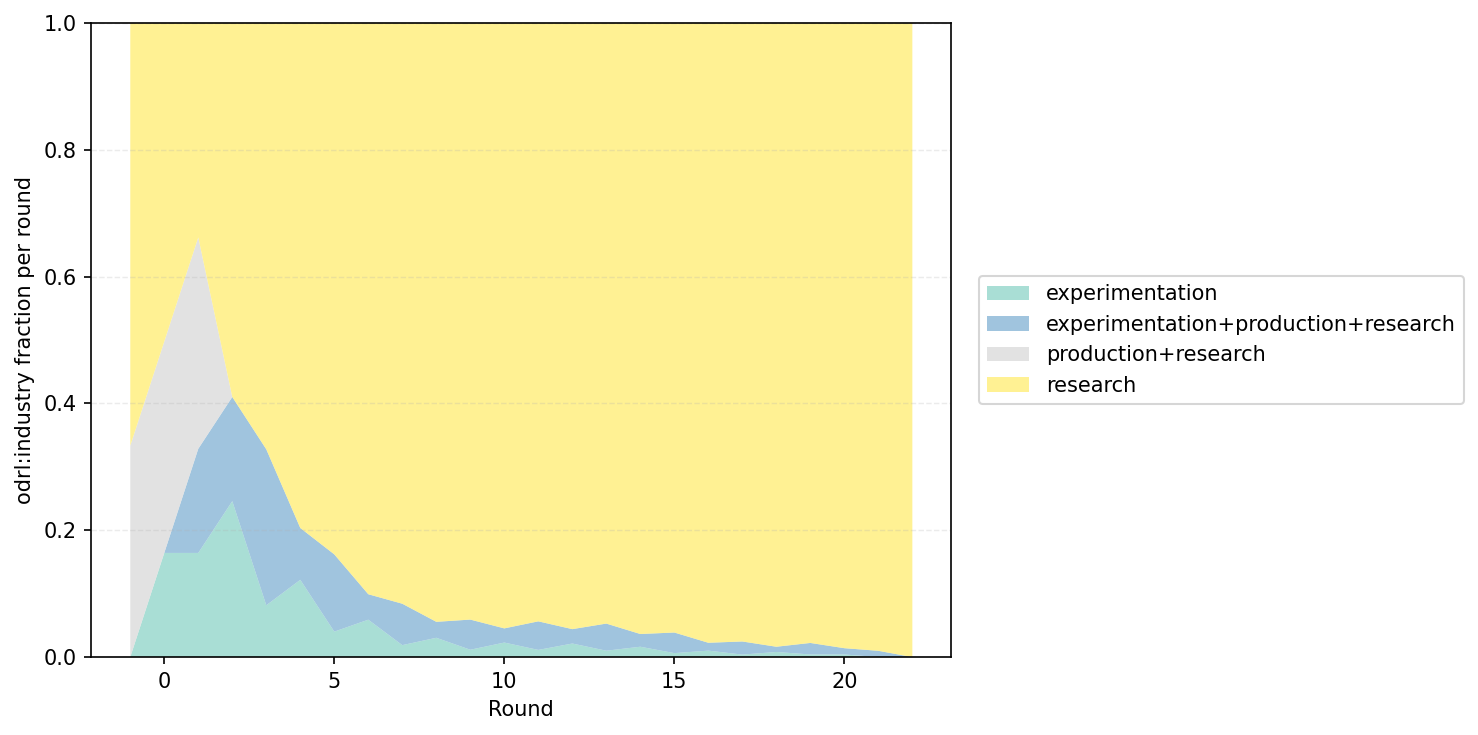

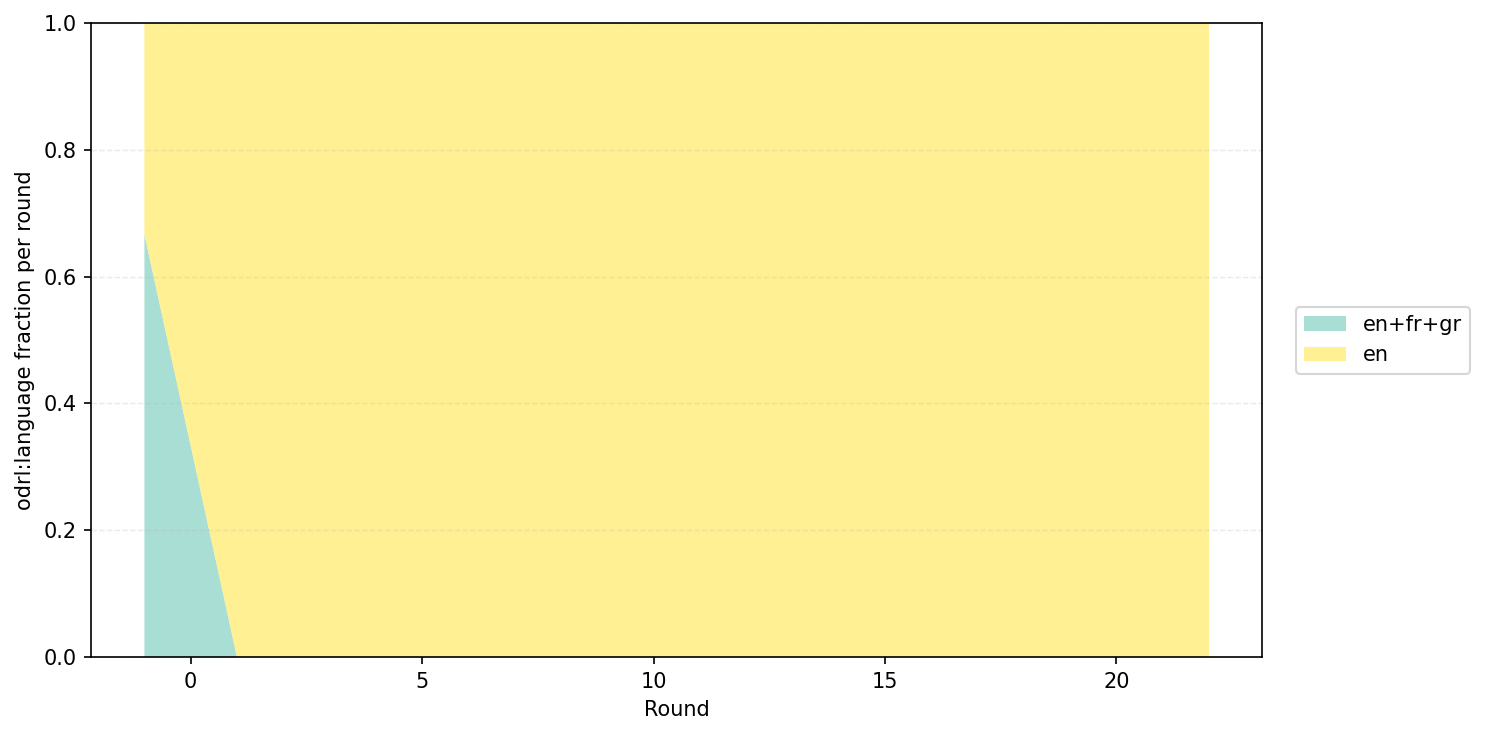

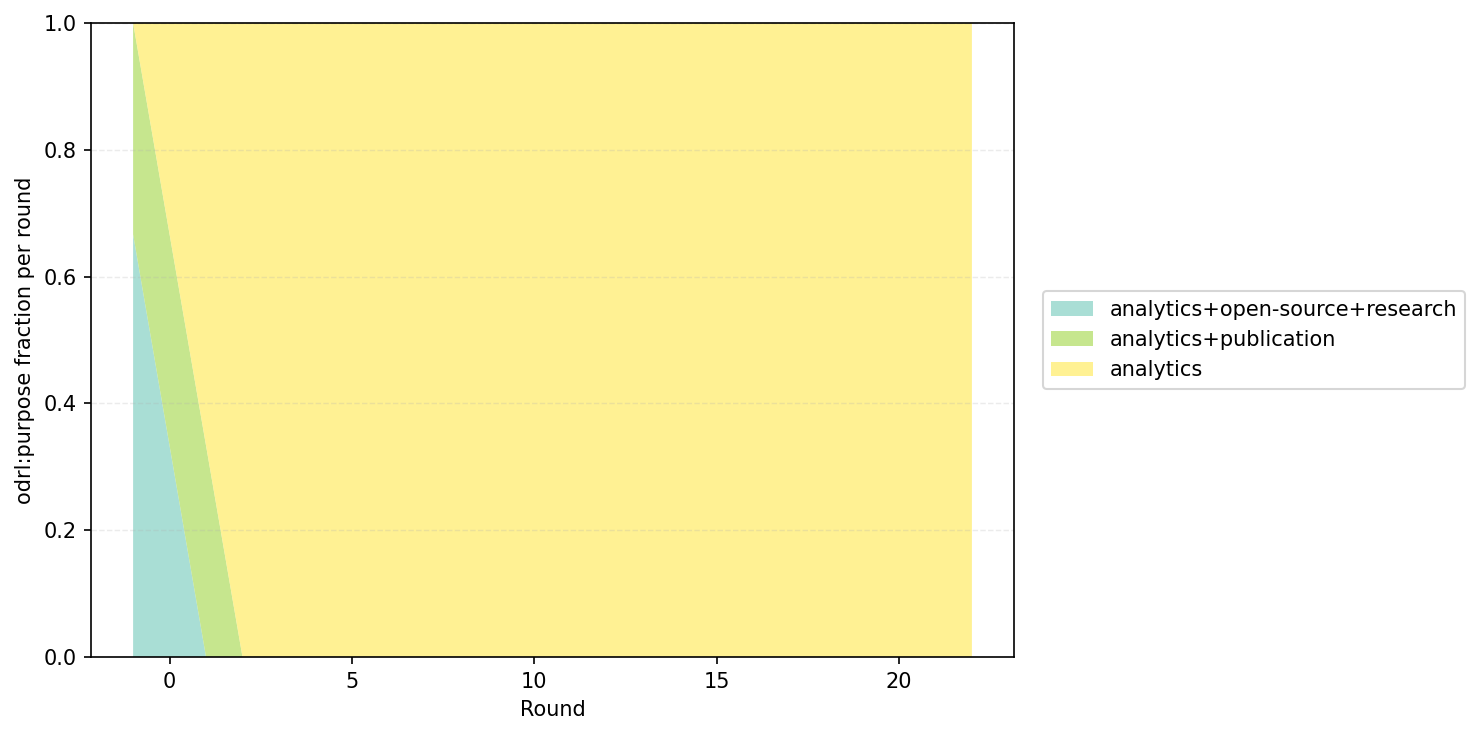

In [143]:
for cat in list(data[0]['data'].keys())[-4:]:
    plot_category_area_per_round(data, cat, round95=round95, outfile=f'{cat}.png', min_share=0.00)
    # plot_category_lines_per_round(data, cat, outfile=f'{cat}.png')

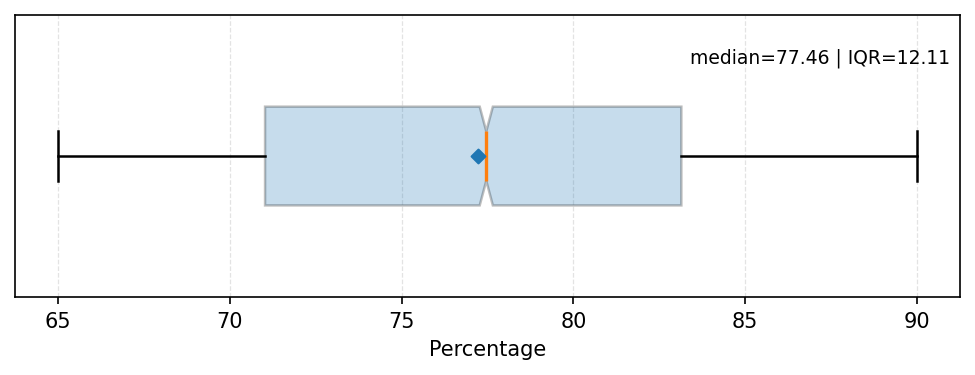

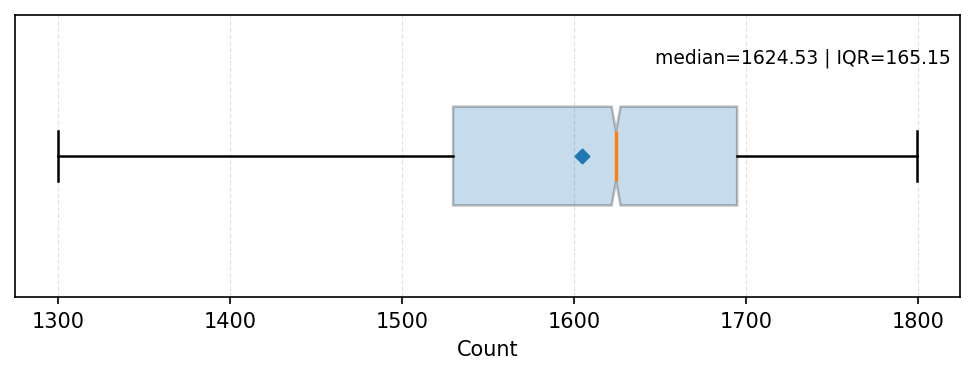

C:\Users\isotiropoulos\AppData\Local\Temp\ipykernel_13616\535304838.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([_seconds_to_xsd_duration(t) for t in ticks])


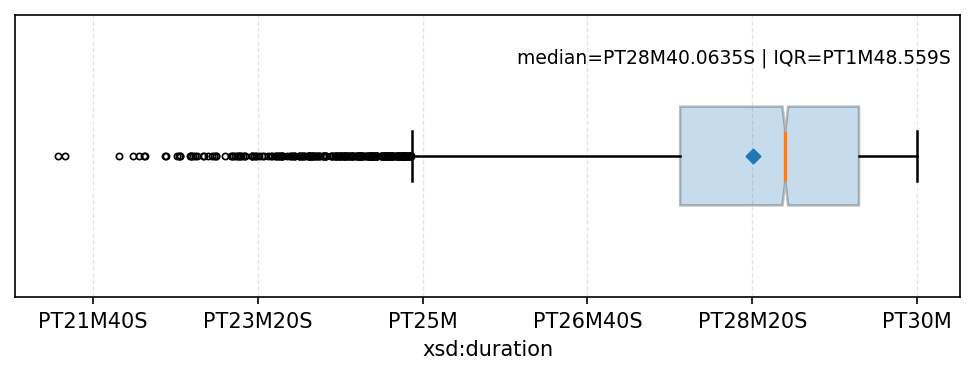

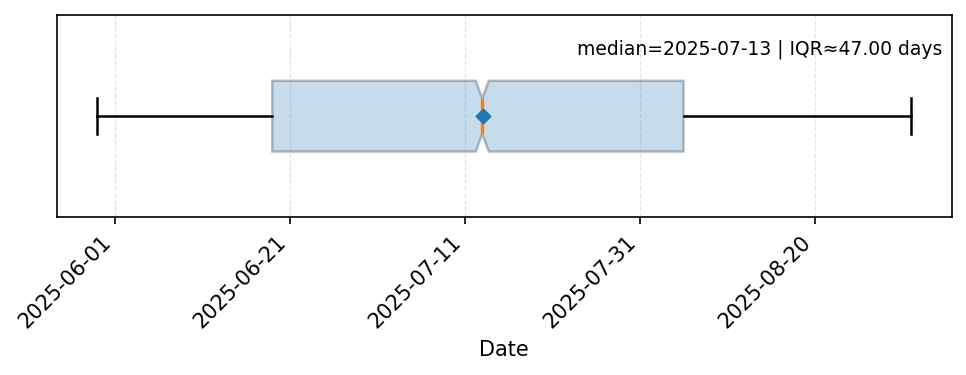

In [144]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import matplotlib.dates as mdates
import isodate  # pip install isodate


# -----------------------------
# Helpers
# -----------------------------
def extract_final(runs, key, transform=None, *, as_float=False):
    """
    Extract the final agreed value for key from each run.
    - as_float=True: cast to float (numeric keys)
    - as_float=False: keep raw (strings for date/duration)
    """
    vals = []
    for run in runs:
        v = run["data"][key][-1]
        if transform:
            v = transform(v)
        if as_float:
            vals.append(float(v))
        else:
            vals.append(v)
    return np.array(vals, dtype=float if as_float else object)


def _summary_stats(vals):
    vals = np.asarray(vals, dtype=float)
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    iqr = q3 - q1
    return q1, med, q3, iqr


def _is_duration_str(x):
    return isinstance(x, str) and x.strip().upper().startswith("P")  # PT.. or P..

def _is_date_str(x):
    if not isinstance(x, str):
        return False
    s = x.strip()
    return len(s) >= 10 and s[4] == "-" and s[7] == "-"

def _parse_duration_to_seconds(x):
    d = isodate.parse_duration(str(x))
    return float(d.total_seconds())

def _seconds_to_xsd_duration(sec):
    return isodate.duration_isoformat(timedelta(seconds=float(sec)))

def _parse_date_to_datetime(x):
    s = str(x).strip()
    try:
        return datetime.fromisoformat(s)
    except ValueError:
        return datetime.strptime(s[:10], "%Y-%m-%d")
        
def plot_final_distribution_pretty(vals, xlabel, *,
                                   show_mean=True, notch=True,
                                   kind="auto",
                                   rotate_date_ticks=45,
                                   outfile: str = "final_distribution.png",
                                   dpi: int = 300):
    raw = list(vals)

    # detect kind
    if kind == "auto":
        first = next((v for v in raw if v is not None), None)
        if _is_duration_str(first):
            kind = "duration"
        elif _is_date_str(first):
            kind = "date"
        else:
            kind = "numeric"

    # convert to numeric axis values
    if kind == "duration":
        xs = np.array([_parse_duration_to_seconds(v) for v in raw], dtype=float)
    elif kind == "date":
        dts = [_parse_date_to_datetime(v) for v in raw]
        xs = np.array([mdates.date2num(dt) for dt in dts], dtype=float)
    else:
        xs = np.asarray(raw, dtype=float)

    q1, med, q3, iqr = _summary_stats(xs)

    fig, ax = plt.subplots(figsize=(6.6, 2.6), dpi=150)

    bp = ax.boxplot(
        xs,
        vert=False,
        notch=notch,
        showfliers=True,
        widths=0.35,
        patch_artist=True,
        boxprops=dict(linewidth=1.2),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        medianprops=dict(linewidth=1.6),
        flierprops=dict(marker="o", markersize=3, markerfacecolor="none", markeredgewidth=0.8),
    )

    for b in bp["boxes"]:
        b.set_alpha(0.25)

    if show_mean:
        ax.scatter([xs.mean()], [1], marker="D", s=22, zorder=3)

    ax.set_yticks([])
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.35)

    # ❌ no title (removed)

    # Format x-axis depending on kind
    if kind == "duration":
        ticks = ax.get_xticks()
        ax.set_xticklabels([_seconds_to_xsd_duration(t) for t in ticks])
        ax.text(
            0.99, 0.88,
            f"median={_seconds_to_xsd_duration(med)} | IQR={_seconds_to_xsd_duration(iqr)}",
            transform=ax.transAxes,
            ha="right", va="top",
            fontsize=9
        )

    elif kind == "date":
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
        for label in ax.get_xticklabels():
            label.set_rotation(rotate_date_ticks)
            label.set_ha("right")

        ax.text(
            0.99, 0.88,
            f"median={mdates.num2date(med).strftime('%Y-%m-%d')} | IQR≈{iqr:.2f} days",
            transform=ax.transAxes,
            ha="right", va="top",
            fontsize=9
        )

    else:
        ax.text(
            0.99, 0.88,
            f"median={med:.2f} | IQR={iqr:.2f}",
            transform=ax.transAxes,
            ha="right", va="top",
            fontsize=9
        )

    xmin, xmax = float(np.min(xs)), float(np.max(xs))
    pad = 0.05 * (xmax - xmin if xmax > xmin else 1.0)
    ax.set_xlim(xmin - pad, xmax + pad)

    fig.tight_layout()

    # ✅ save AND show
    fig.savefig(outfile, dpi=dpi, bbox_inches="tight")
    plt.show()

# -----------------------------
# Example calls (adjust 'data' variable name to yours)
# -----------------------------
# Numeric
plot_final_distribution_pretty(
    extract_final(data, "percentage", as_float=True),
    "Percentage",
    outfile='percentage_box.png',
    kind="numeric"
)

plot_final_distribution_pretty(
    extract_final(data, "count", as_float=True),
    "Count",
    outfile='count_box.png',
    kind="numeric"
)

# Duration
plot_final_distribution_pretty(
    extract_final(data, "delayPeriod", as_float=False),
    "xsd:duration",
    outfile='delay_box.png',
    kind="duration"
)

# Date
plot_final_distribution_pretty(
    extract_final(data, "absoluteTemporalPosition", as_float=False),
    "Date",
    outfile='date_box.png',
    kind="date",
    rotate_date_ticks=45
)


In [10]:
from collections import Counter
import math
import matplotlib.pyplot as plt

def normalize_agreed(v):
    # enum "en" → ("en",)
    # set ["en"] → ("en",)
    if isinstance(v, list):
        return tuple(sorted(v))
    return (v,)


def shannon_entropy(cnt: Counter) -> float:
    total = sum(cnt.values())
    H = 0.0
    for c in cnt.values():
        p = c / total
        H -= p * math.log2(p)
    return H

def robustness_from_agreed_values(runs, keys):
    """
    FINAL RESULTS ONLY:
    agreed value for each run is run['data'][key][-1].
    """
    rows = []
    for key in keys:
        agreed = []
        for run in runs:
            seq = run.get("data", {}).get(key, None)
            if not seq:
                continue
            if len(normalize_agreed(seq[-1])) == 0:
                print(seq)
            agreed.append(normalize_agreed(seq[-1]))
            

        cnt = Counter(agreed)
        total = sum(cnt.values())

        if total == 0:
            rows.append(dict(issue=key, dominant=None, share=0.0, unique=0, entropy=0.0, n=0))
            continue

        dominant, dom_c = cnt.most_common(1)[0]
        rows.append(dict(
            issue=key,
            dominant=dominant,
            share=100.0 * dom_c / total,
            unique=len(cnt),
            entropy=shannon_entropy(cnt),
            n=total,
            _counts=cnt,   # keep counts if you want plots
        ))
    return rows

def print_latex_robustness_table(rows, caption, label):
    print(r"\begin{table}[t]")
    print(r"\centering")
    print(r"\begin{tabular}{l l c c c}")
    print(r"\toprule")
    print(r"Issue & Dominant agreement & Share (\%) & Unique & Entropy \\")
    print(r"\midrule")
    for r in rows:
        dom = r["dominant"]
        if isinstance(dom, tuple):
            dom = r"\{" + ", ".join(map(str, dom)) + r"\}"
        elif dom is None:
            dom = r"\textemdash"
        print(f"{r['issue']} & {dom} & {r['share']:.1f} & {r['unique']} & {r['entropy']:.2f} \\\\")
    print(r"\bottomrule")
    print(r"\end{tabular}")
    print(rf"\caption{{{caption}}}")
    print(rf"\label{{{label}}}")
    print(r"\end{table}")

In [13]:
keys = ["fileFormat", "language", "industry", "purpose"]
set_enum_robustness = robustness_from_agreed_values(data, keys)
set_enum_robustness


[{'issue': 'fileFormat',
  'dominant': ('JSON',),
  'share': 100.0,
  'unique': 1,
  'entropy': 0.0,
  'n': 9902,
  '_counts': Counter({('JSON',): 9902})},
 {'issue': 'language',
  'dominant': ('en',),
  'share': 100.0,
  'unique': 1,
  'entropy': 0.0,
  'n': 9902,
  '_counts': Counter({('en',): 9902})},
 {'issue': 'industry',
  'dominant': ('research',),
  'share': 100.0,
  'unique': 1,
  'entropy': 0.0,
  'n': 9902,
  '_counts': Counter({('research',): 9902})},
 {'issue': 'purpose',
  'dominant': ('analytics',),
  'share': 100.0,
  'unique': 1,
  'entropy': 0.0,
  'n': 9902,
  '_counts': Counter({('analytics',): 9902})}]